# LART, from the inside: replicating *"On the Benefits of 3D Pose and Tracking for Human Action Recognition"*

Rajasegaran, Pavlakos, Kanazawa, Feichtenhofer, Malik, **CVPR 2023**. This notebook pairs every idea in the
paper with code that runs on the **released 45.1-mAP model and the authors' own AVA tracks**.

| Part | Topic | Paper |
|---|---|---|
| **A** | What a *tracklet* is: 3D pose, 3D joints, appearance, labels. The person as a 3D mesh. | §1, §3 |
| **B** | The model: tokens, masking, the transformer, per-frame action predictions | §3.1–3.2, §4.4 |
| **C** | **Replication** of the AVA v2.2 number (45.1), and comparison with the authors' own per-class results | Tables 3, 6 |
| **D** | Summary, and LART vs. TubeR | |

**Setup:** `python tools/setup_lart.py --smpl <SMPL neutral pkl>` and `python tools/download_ava_val.py` (see
`docs/02_replication_guide.md`). The full evaluation (2.5 h) is run once with `python eval_ava.py`; Part C loads its result.

## 0. Setup

In [1]:
import os, sys, json, time, glob
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import lartlab                                   # HOME -> ./cache (PHALP's CACHE_DIR), upstream code on sys.path
from lartlab import evaluate as E
import numpy as np, torch, joblib
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
device = "cuda" if torch.cuda.is_available() else "cpu"
RERUN = False                                    # True: recompute cached evaluations (slow)
DATA = ROOT / "data" / "ava_val"
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if device == "cuda" else "cpu")
print("tracks on disk:", len(os.listdir(DATA)), "| complete:", (ROOT / "data/ava_val.COMPLETE").exists())

torch 2.11.0+cu128 | NVIDIA GeForce RTX 5060 Laptop GPU
tracks on disk: 97148 | complete: True


---
# Part A: the Lagrangian view, and what a tracklet contains

## A1. Eulerian vs. Lagrangian, on a real AVA person

Standard video models (TubeR, SlowFast, MViT, Hiera) are **Eulerian**: to classify a person they crop features at
the person's box **in the middle frame**, as if watching the river from a fixed point on the bank. LART is
**Lagrangian**: it follows the person (the track) through time, like drifting with the river.

How much of a moving person stays inside the fixed middle-frame box? We take a real AVA track and measure, at
every frame, the overlap (IoU) between the person's actual box and the box frozen at the middle frame.

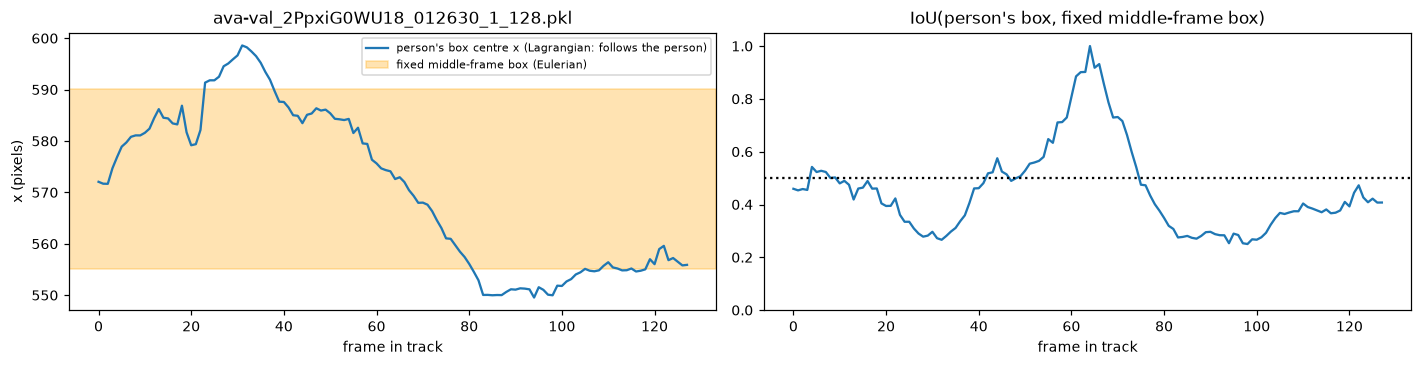

the person is inside the fixed box (IoU>0.5) in only 29% of the 128 frames


In [2]:
def iou(a, b):  # boxes as x, y, w, h
    ax2, ay2, bx2, by2 = a[0] + a[2], a[1] + a[3], b[0] + b[2], b[1] + b[3]
    iw, ih = max(0, min(ax2, bx2) - max(a[0], b[0])), max(0, min(ay2, by2) - max(a[1], b[1]))
    return iw * ih / (a[2] * a[3] + b[2] * b[3] - iw * ih)

# pick, among long tracks, the person who spends the most frames OUTSIDE their own middle-frame box
cands = sorted(f for f in os.listdir(DATA) if f.endswith("_128.pkl"))[:600]
def frac_outside(f):
    t = joblib.load(DATA / f); b = np.array(t["frame_bbox"]); W = t["frame_size"][0][1]
    if (b[:, 2:] < 20).any() or (b[:, 2] > 0.4 * W).any():   # skip degenerate / frame-filling boxes
        return -1
    return np.mean([iou(x, b[len(b) // 2]) < 0.5 for x in b])
TRACK = max(cands, key=frac_outside)
trk = joblib.load(DATA / TRACK)
boxes = np.array(trk["frame_bbox"]); mid = len(boxes) // 2
ious = [iou(b, boxes[mid]) for b in boxes]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
cx = boxes[:, 0] + boxes[:, 2] / 2
ax[0].plot(cx, label="person's box centre x (Lagrangian: follows the person)")
ax[0].axhspan(boxes[mid, 0], boxes[mid, 0] + boxes[mid, 2], color="orange", alpha=0.3, label="fixed middle-frame box (Eulerian)")
ax[0].set_xlabel("frame in track"); ax[0].set_ylabel("x (pixels)"); ax[0].legend(fontsize=7); ax[0].set_title(TRACK)
ax[1].plot(ious); ax[1].axhline(0.5, ls=":", c="k"); ax[1].set_ylim(0, 1.05)
ax[1].set_xlabel("frame in track"); ax[1].set_title("IoU(person's box, fixed middle-frame box)")
plt.tight_layout(); plt.show()
print(f"the person is inside the fixed box (IoU>0.5) in only {np.mean(np.array(ious) > 0.5):.0%} of the {len(boxes)} frames")

## A2. Anatomy of a tracklet file

The authors ran PHALP on all of AVA and released one `.pkl` per person-track (file name:
`<dataset>_<video>_<keyframe>_<trackid>_<length>.pkl`). Every field is per frame:

In [3]:
for k, v in trk.items():
    if isinstance(v, np.ndarray): desc = f"array {v.shape}"
    elif isinstance(v, dict):     desc = f"dict of {len(v)} entries, each {np.shape(next(iter(v.values())))}"
    else:                         desc = f"list of {len(v)}, e.g. {str(v[0])[:60]}"
    print(f"{k:20s} {desc}")

fid                  array (128, 1, 1)
pose_shape           array (128, 1, 229)
3d_joints            array (128, 1, 45, 3)
camera               array (128, 1, 3)
camera_bbox          array (128, 1, 3)
action_label_gt      array (128, 1, 80)
action_label_psudo   dict of 23 entries, each (1, 80)
has_gt               array (128, 1, 1)
has_detection        array (128, 1, 1)
apperance_index      array (128, 1, 1)
apperance_dict       dict of 23 entries, each (1, 2048)
frame_name           list of 128, e.g. /datasets01/AVA/080720/frames/2PpxiG0WU18/2PpxiG0WU18_012566
frame_size           list of 128, e.g. [480 854]
frame_bbox           list of 128, e.g. [544.2138   221.37125   55.709656 140.95566 ]
frame_conf           list of 128, e.g. 0.97668284


| field | meaning |
|---|---|
| `pose_shape` (229) | SMPL **global orientation** (3×3 = 9) + **body pose** (23 joints × 3×3 = 207) + **shape** β (10) + camera (3) |
| `3d_joints` (45×3) | 3D joints of the SMPL body in camera coordinates (added to the camera translation → 135 numbers) |
| `apperance_dict` / `_index` | **contextualised appearance**: Hiera features (2048-d), computed every ~6 frames and shared by the frames in between |
| `action_label_gt`, `has_gt` | AVA ground truth (`has_gt=2`, the frames around the key frame) or pseudo-labels (`has_gt=1`) |
| `frame_bbox`, `frame_conf` | PHALP's detection box per frame. **This box is what gets scored on AVA** |

## A3. The person as a 3D mesh: what "3D pose" means here

The 229 numbers become a full body. We feed them to the SMPL model (your licensed copy), which gives 6,890
vertices and 45 joints. The representation is **amodal**: the whole body exists even when it's occluded or out
of frame, and it's **viewpoint-invariant** (body pose is separate from global orientation).

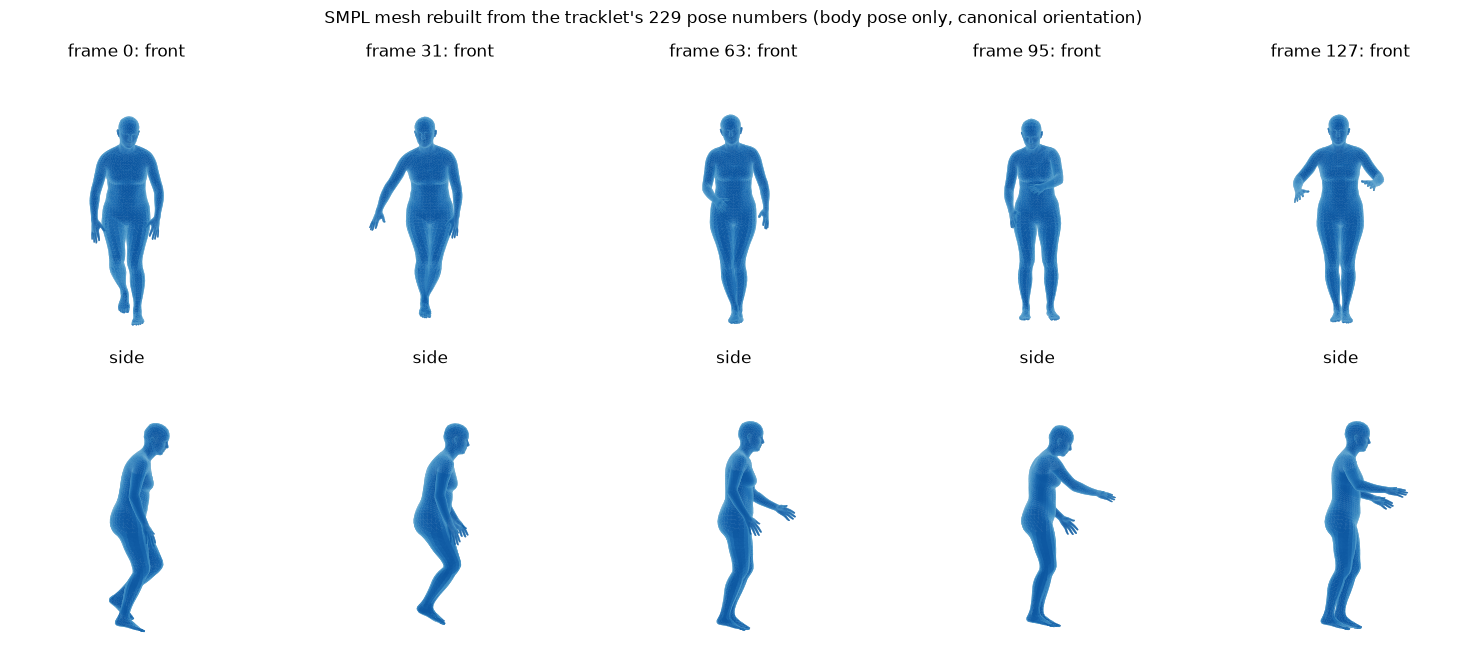

In [4]:
import smplx
from phalp.configs.base import CACHE_DIR
smpl = smplx.SMPLLayer(model_path=f"{CACHE_DIR}/phalp/3D/models/smpl/SMPL_NEUTRAL.pkl", num_betas=10)
ps = torch.tensor(trk["pose_shape"][:, 0], dtype=torch.float32)
go, bp, betas = ps[:, :9].view(-1, 1, 3, 3), ps[:, 9:216].view(-1, 23, 3, 3), ps[:, 216:226]
with torch.no_grad():
    body = smpl(global_orient=torch.eye(3).expand(len(ps), 1, 3, 3), body_pose=bp, betas=betas)  # canonical view
V, F = body.vertices.numpy(), smpl.faces
from matplotlib.collections import PolyCollection
def draw_mesh(ax, v, axes=(0, 1), depth=2):
    tri = v[F]                                                    # (13776, 3, 3)
    n = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]); n /= np.linalg.norm(n, axis=1, keepdims=True) + 1e-9
    order = np.argsort(tri[:, :, depth].mean(1))                  # far -> near (camera looks along +depth)
    shade = 0.35 + 0.65 * np.abs(n[order, depth])
    ax.add_collection(PolyCollection(tri[order][:, :, list(axes)], facecolors=plt.cm.Blues(0.25 + 0.6 * shade), edgecolors="none"))
    ax.set_xlim(-0.9, 0.9); ax.set_ylim(-1.2, 0.9); ax.set_aspect("equal"); ax.axis("off")
frames = np.linspace(0, len(ps) - 1, 5).astype(int)
fig, axs = plt.subplots(2, 5, figsize=(14, 6))
for i, f in enumerate(frames):
    draw_mesh(axs[0, i], V[f], axes=(0, 1), depth=2); axs[0, i].set_title(f"frame {f}: front")
    draw_mesh(axs[1, i], V[f], axes=(2, 1), depth=0); axs[1, i].set_title("side")
plt.suptitle("SMPL mesh rebuilt from the tracklet's 229 pose numbers (body pose only, canonical orientation)", y=0.98); plt.tight_layout(); plt.show()

## A4. Appearance features and labels along the track

The appearance model (Hiera) is expensive, so it runs **every ~6 frames** and its feature is reused in between.
The labels show LART's dense supervision: ground truth around the key frame, and **pseudo-labels** from a teacher
model everywhere else.

0 of 128 frames have no appearance feature (the dataset feeds zeros there)


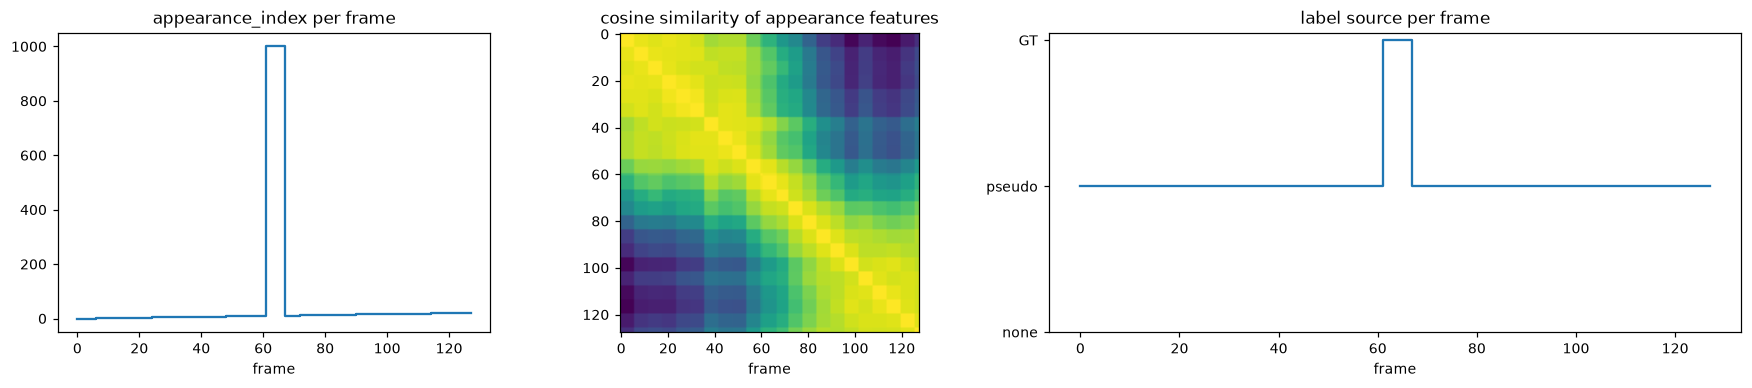

ground-truth actions at the key frame: ['talk to (e.g., self, a person, a group)']


In [5]:
idx = trk["apperance_index"][:, 0, 0]                 # -1 = no appearance feature for this frame
D = len(next(iter(trk["apperance_dict"].values()))[0])
feats = np.stack([trk["apperance_dict"][i][0] if i != -1 else np.zeros(D) for i in idx])   # as the dataset does
nrm = feats / (np.linalg.norm(feats, axis=1, keepdims=True) + 1e-8)
sim = nrm @ nrm.T
print(f"{(idx == -1).sum()} of {len(idx)} frames have no appearance feature (the dataset feeds zeros there)")
from lartlab import labels as LB
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.6]})
ax[0].step(range(len(idx)), idx, where="post"); ax[0].set_title("appearance_index per frame"); ax[0].set_xlabel("frame")
ax[1].imshow(sim, cmap="viridis"); ax[1].set_title("cosine similarity of appearance features"); ax[1].set_xlabel("frame")
hg = trk["has_gt"][:, 0, 0]
ax[2].plot(hg, drawstyle="steps-post"); ax[2].set_yticks([0, 1, 2], ["none", "pseudo", "GT"]); ax[2].set_xlabel("frame")
ax[2].set_title("label source per frame")
plt.tight_layout(); plt.show()
k = np.where(hg == 2)[0]
if len(k):
    gt = np.where(trk["action_label_gt"][k[0], 0] > 0)[0] + 1
    print("ground-truth actions at the key frame:", [LB.AVA80[i] for i in gt])

---
# Part B: the model

## B1. Build the released LART-Hiera model and load the checkpoint

W1020 18:16:10.216000 22828 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


[10/20 18:16:10] WARNING  index 0 is out of bounds for axis 0 with size 0                           rank_zero.py:42

                 INFO     Storage folder : C:\Users\itayb\Desktop\Technion\Year A\Semester          rank_zero.py:42
                          B\CVProject\lart_replication\outputs\_model                                              

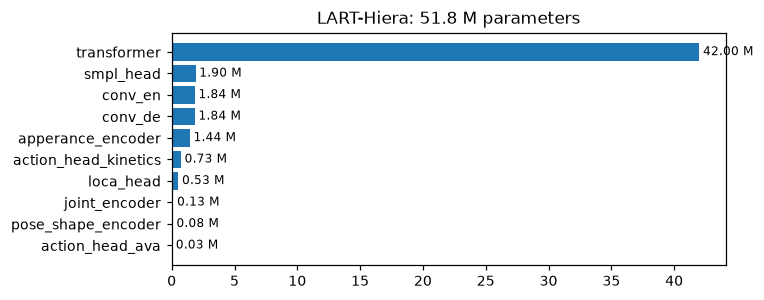

In [6]:
cfg = E.load_config()
model = E.load_model(cfg, device=device)
groups = {n: sum(p.numel() for p in m.parameters()) / 1e6 for n, m in model.encoder.named_children()}
groups = {k: v for k, v in sorted(groups.items(), key=lambda x: -x[1]) if v > 0.01}
fig, ax = plt.subplots(figsize=(7, 2.8)); ax.barh(list(groups), list(groups.values())); ax.invert_yaxis()
for i, v in enumerate(groups.values()): ax.text(v + 0.3, i, f"{v:.2f} M", va="center", fontsize=8)
ax.set_title(f"LART-Hiera: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters"); plt.tight_layout(); plt.show()
print({k: cfg[k] for k in ["frame_length", "max_people", "in_feat", "test_type", "mask_type_test"]},
      "| transformer:", dict(cfg.transformer)["depth"], "layers,", dict(cfg.transformer)["heads"], "heads")

## B2. From a tracklet to tokens

The dataset (`PHALP_action_dataset`) turns a track into a **125 frames × 5 people** grid. Slot 0 is the person
of interest; slots 1–4 hold other people from the same video. Each cell becomes one 512-d token:

$$\text{token}_{t,i} = \underbrace{f_{pose}(\theta,\psi,\beta)}_{229\to128} \oplus \underbrace{f_{joints}(J_{3D})}_{135\to128} \oplus \underbrace{f_{app}(U)}_{2048\to256} \;+\; PE(t, i)$$

Cells with no detection get the learned **[MASK]** token. Below: one real sample, which cells hold a detection,
and the 2D sinusoidal position embedding over (time, person).

[10/20 18:16:12] INFO     Total number of tracks: 97148                                             rank_zero.py:42

                 INFO     Total number of frames: 9948946                                           rank_zero.py:42

                 INFO     Number of tracks: 97148                                                   rank_zero.py:42

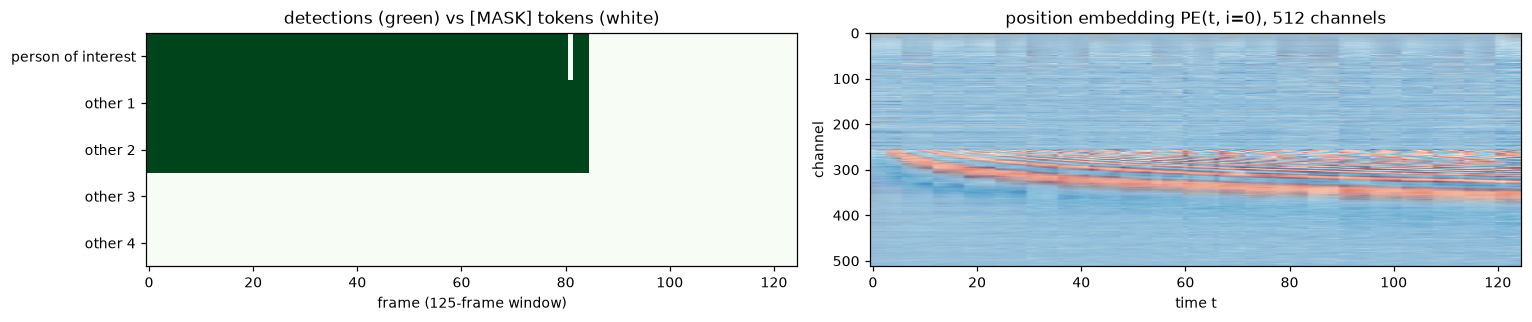

In [7]:
ds_small = E.build_val_dataset(cfg, limit=200)
np.random.seed(0)
sample = max(range(60), key=lambda i: ds_small[i][0]["has_detection"][:, 1:].sum())   # one with other people
inp, out, meta, vname = ds_small[sample]
print("sample:", vname, {k: v.shape for k, v in inp.items()})
fig, ax = plt.subplots(1, 2, figsize=(14, 3))
ax[0].imshow(inp["has_detection"][:, :, 0].T, aspect="auto", cmap="Greens", interpolation="nearest")
ax[0].set_yticks(range(5), ["person of interest", "other 1", "other 2", "other 3", "other 4"])
ax[0].set_xlabel("frame (125-frame window)"); ax[0].set_title("detections (green) vs [MASK] tokens (white)")
pe = model.encoder.pos_embedding.detach().cpu().numpy()          # (512, 250, 10)
ax[1].imshow(pe[:, :125, 0], aspect="auto", cmap="RdBu"); ax[1].set_xlabel("time t"); ax[1].set_ylabel("channel")
ax[1].set_title("position embedding PE(t, i=0), 512 channels"); plt.tight_layout(); plt.show()

## B3. Inside the forward pass

We feed the sample through the encoders and the 16-layer transformer, recording shapes with hooks, then read the
per-frame AVA action probabilities for the person of interest.

In [8]:
shapes = {}
def rec(n):
    return lambda m, i, o: shapes.__setitem__(n, tuple((o[0] if isinstance(o, tuple) else o).shape))
hooks = [model.encoder.pose_shape_encoder.register_forward_hook(rec("pose encoder 229->128")),
         model.encoder.joint_encoder.register_forward_hook(rec("joint encoder 135->128")),
         model.encoder.apperance_encoder.register_forward_hook(rec("appearance encoder 2048->256")),
         model.encoder.transformer.register_forward_hook(rec("transformer output (625 tokens)")),
         model.encoder.action_head_ava[0].register_forward_hook(rec("AVA action head (60 classes)"))]
batch = torch.utils.data.default_collate([ds_small[sample]])
tok = {k: v.to(device) for k, v in batch[0].items()}
with torch.no_grad():
    output, smpl_out, _ = model(tok, cfg.mask_type_test)
for h in hooks: h.remove()
for k, v in shapes.items(): print(f"{k:34s} {v}")
probs = torch.sigmoid(smpl_out["pred_actions_ava"]).view(1, 125, 5, -1)[0, :, 0].cpu().numpy()   # (125, 60)

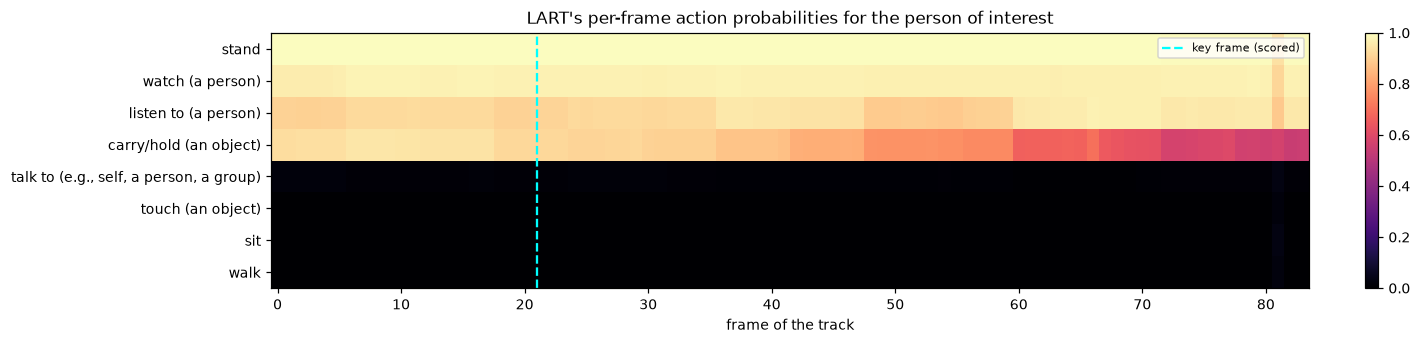

In [9]:
valid = np.load(f"{CACHE_DIR}/lart/ava_valid_classes.npy")          # model output j -> AVA id valid[j]
n_frames = int(inp["has_detection"][:, 0].sum())
kf = E.key_frame_index(meta, vname)
top = np.argsort(-probs[:n_frames].mean(0))[:8]
fig, ax = plt.subplots(figsize=(13, 3.2))
im = ax.imshow(probs[:n_frames, top].T, aspect="auto", cmap="magma", vmin=0, vmax=1)
ax.set_yticks(range(len(top)), [LB.AVA80[valid[j]] for j in top]); ax.set_xlabel("frame of the track")
if kf is not None: ax.axvline(kf, color="cyan", ls="--", label="key frame (scored)")
ax.legend(loc="upper right", fontsize=7); plt.colorbar(im, ax=ax, fraction=0.02)
ax.set_title("LART's per-frame action probabilities for the person of interest"); plt.tight_layout(); plt.show()
gt_ids = np.where(out["action_label_ava"][kf, 0, 0] > 0)[0] if kf is not None else []
print("ground truth at the key frame:", [LB.AVA80[valid[j]] for j in gt_ids if j < 60])
# (these are exactly the scores the official evaluation pipeline writes for this track - LART is very decisive:
#  on AVA val ~92% of its class scores are < 0.01)
w = 6
print("prediction scored (mean of sigmoid over +-6 frames), top-5:",
      [(LB.AVA80[valid[j]], round(float(p), 2)) for j, p in
       sorted(enumerate(probs[max(0, kf - w):kf + w].mean(0)), key=lambda x: -x[1])[:5]])

---
# Part C: replicating the paper's number

`eval_ava.py` runs the authors' evaluation pipeline unchanged (dataset → `validation_step` → AVA CSV → official
ActivityNet scorer) over **all 64 AVA v2.2 validation videos**. It takes about 1–2 h on one GPU, so we load its
saved result here. Re-run it with `python eval_ava.py`.

In [10]:
full = ROOT / "outputs" / "eval_all_full_avg.6" / "summary.json"
if RERUN or not full.exists():
    print(os.popen(f'"{sys.executable}" eval_ava.py --workers 6').read()[-600:])
S = json.loads(full.read_text())
print(f"our replication: {S['mAP']:.2f} mAP on {S['tracks']} tracks ({S['minutes']} min)   |   paper: 45.1")
# the checkpoint archive also contains the authors' own evaluation result
theirs = joblib.load(ROOT / "logs/LART_Hiera/0/results/2.pkl")[0]
T = {LB.per_class_name(k): v * 100 for k, v in theirs.items() if "PerformanceByCategory/AP@" in k}
print(f"authors' own saved result in the archive: {theirs['PascalBoxes_Precision/mAP@0.5IOU'] * 100:.2f} mAP")

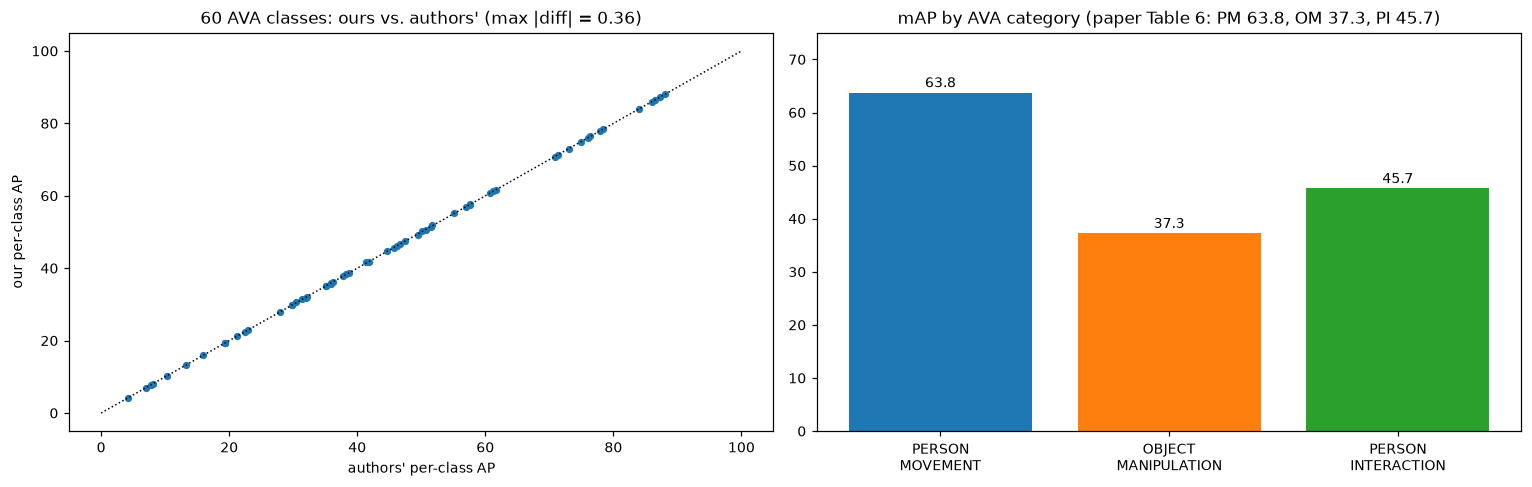

In [11]:
common = [c for c in S["per_class_AP"] if c in T and not np.isnan(T[c])]
ours = np.array([S["per_class_AP"][c] for c in common]); auth = np.array([T[c] for c in common])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(auth, ours, s=14); ax[0].plot([0, 100], [0, 100], "k:", lw=1)
ax[0].set_xlabel("authors' per-class AP"); ax[0].set_ylabel("our per-class AP")
ax[0].set_title(f"60 AVA classes: ours vs. authors' (max |diff| = {np.abs(ours - auth).max():.2f})")
cat = LB.category_map()
for c_name, color in (("PERSON_MOVEMENT", "C0"), ("OBJECT_MANIPULATION", "C1"), ("PERSON_INTERACTION", "C2")):
    sel = [i for i, c in enumerate(common) if cat.get(c) == c_name]
    ax[1].bar(c_name.replace("_", "\n"), np.mean(ours[sel]), color=color)
    ax[1].text(c_name.replace("_", "\n"), np.mean(ours[sel]) + 1, f"{np.mean(ours[sel]):.1f}", ha="center")
ax[1].set_title("mAP by AVA category (paper Table 6: PM 63.8, OM 37.3, PI 45.7)"); ax[1].set_ylim(0, 75)
plt.tight_layout(); plt.show()

---
# Part D: summary, and LART vs. TubeR

* The released LART-Hiera model, the authors' AVA validation tracks and their evaluation code give
  **45.11 mAP** here, against **45.1** in the paper (and 45.105 in the authors' own saved result).
* LART classifies each **person track** (≈4 s): 3D body pose (SMPL), 3D joints and appearance per frame,
  with the other people at the same moment as extra tokens, via a 16-layer transformer.
* Running it on new videos needs the "front half" (detection → 3D bodies → tracking → appearance), which runs on
  Linux: see `../SERVER.md` and `run.py --model lart`.

| | TubeR (first part of this project) | LART |
|---|---|---|
| View | Eulerian: features at fixed space-time locations | Lagrangian: follows each person |
| Input | 32 RGB frames (≈2 s) | tracks up to 125 frames (≈4 s) of 3D pose + 3D joints + appearance |
| People | 15 DETR queries, found by the model | external detector + 3D tracker (PHALP) |
| AVA v2.2 | 31.1 mAP | **45.1** mAP (replicated in Part C) |
| Running on a new video | 1 network (fast) | 5 networks: ViTDet, HMR 2.0, PHALP, Hiera/MViT, LART (Linux, slow) |